In [5]:
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolvePNM
from RMFsolver.phase_velocity import (
    PNM_n,
    edensNM_n,
    sNM_n,
    solve_front_adiabatic,
    solve_front_energy_conserving,
    solve_front_isothermal,
)
from RMFsolver.SQMsolver import PQM, edensQM, nK_QM


output_dir = Path("csv_share")
output_dir.mkdir(exist_ok=True)

# Profile generation switches. Energy-conserving is always generated; these
# slower comparison profiles are opt-in.
SAVE_ENTROPY_HU_CONST_PROFILE = False
SAVE_ISOTHERMAL_PROFILE = False
SAVE_TIMESTAMPED_COPIES = True
run_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

n0 = 0.16 * const.MeV_fm**3
T_N = 10.0
nB_N = 3.0 * n0
B14 = 180.0
aQstar = 0.3
ms = 0.0
NM_type = "PNM"
param = para.paraQMCRMF3
profile_suffix = "T10MeV_B14_180MeV_nBN_3n0_aQstar_0p3"
ENERGY_TOL_BVP = 1.0e-8
ENERGY_MAX_NODES = 50000
ENERGY_JB_BOUNDS = (1.0e-5, 5.0)


profile_columns = [
    "dummy",
    "x",
    "a",
    "u",
    "P",
    "e",
    "h",
    "nB",
    "nK",
    "muB",
    "muK",
    "T",
    "h_over_nB",
    "P_over_e",
    "D",
    "gamma",
    "eta",
]


def _profile_x_array(result, n_rows):
    for key in ("x", "x_profile"):
        if key in result:
            values = np.asarray(result[key], dtype=float)
            if values.ndim == 1 and values.size == n_rows:
                return values

    for key in ("s_coord", "s"):
        if key not in result:
            continue
        s_values = np.asarray(result[key], dtype=float)
        if s_values.ndim != 1 or s_values.size != n_rows:
            continue
        if "kappa" in result:
            return -float(result["kappa"]) * np.log1p(-s_values)
        if "lambda" in result:
            return -np.log1p(-s_values) / float(result["lambda"])

    return None


def _validate_profile_array(values, n_rows):
    if values is None:
        return None
    values = np.asarray(values, dtype=float)
    if values.ndim == 0:
        values = np.full(n_rows, float(values), dtype=float)
    if values.ndim != 1 or values.size != n_rows:
        return None
    return values


def _direct_profile_array(result, column, n_rows, fixed_T=None):
    if column == "dummy":
        return np.zeros(n_rows, dtype=float)
    if column == "x":
        return _profile_x_array(result, n_rows)
    if column == "T" and fixed_T is not None and "T_profile" not in result:
        return np.full(n_rows, float(fixed_T), dtype=float)
    if column == "s" and "s_profile" in result:
        return _validate_profile_array(result["s_profile"], n_rows)

    profile_aliases = {
        "P": ("P_profile", "pressure_profile", "P"),
        "e": ("e_profile", "edens_profile", "epsilon_profile", "energy_density_profile", "e"),
        "h": ("h_profile", "enthalpy_profile", "h"),
        "nK": ("nK_profile", "nK"),
        "T": ("T_profile", "T"),
    }
    for key in profile_aliases.get(column, (f"{column}_profile", column)):
        if key in result:
            values = _validate_profile_array(result[key], n_rows)
            if values is not None:
                return values
    return None


def _quark_thermo_inputs(result, n_rows, fixed_T=None):
    muB = _direct_profile_array(result, "muB", n_rows, fixed_T=fixed_T)
    muK = _direct_profile_array(result, "muK", n_rows, fixed_T=fixed_T)
    T = _direct_profile_array(result, "T", n_rows, fixed_T=fixed_T)
    if muB is None or muK is None or T is None:
        return None
    return muB, muK, T


def _compute_quark_eos_array(result, column, n_rows, fixed_T=None):
    thermo_inputs = _quark_thermo_inputs(result, n_rows, fixed_T=fixed_T)
    if thermo_inputs is None:
        return None
    muB, muK, T = thermo_inputs
    values = np.full(n_rows, np.nan, dtype=float)
    for i, (muB_i, muK_i, T_i) in enumerate(zip(muB, muK, T)):
        try:
            if column == "P":
                values[i] = PQM(float(muB_i), float(muK_i), B14, float(T_i), ms=ms)
            elif column == "e":
                values[i] = edensQM(float(muB_i), float(muK_i), B14, float(T_i), ms=ms, include_em=False)
            elif column == "nK":
                values[i] = nK_QM(float(muB_i), float(muK_i), B14, float(T_i), ms=ms)
        except Exception:
            values[i] = np.nan
    return values


def _finite_divide(numerator, denominator):
    values = np.full_like(numerator, np.nan, dtype=float)
    mask = np.isfinite(numerator) & np.isfinite(denominator) & (denominator != 0.0)
    values[mask] = numerator[mask] / denominator[mask]
    return values


def _as_profile_array(result, column, n_rows, fixed_T=None):
    direct = _direct_profile_array(result, column, n_rows, fixed_T=fixed_T)
    if direct is not None:
        return direct

    if column == "P":
        return _compute_quark_eos_array(result, "P", n_rows, fixed_T=fixed_T)
    if column == "nK":
        return _compute_quark_eos_array(result, "nK", n_rows, fixed_T=fixed_T)
    if column == "e":
        h = _direct_profile_array(result, "h", n_rows, fixed_T=fixed_T)
        P = _as_profile_array(result, "P", n_rows, fixed_T=fixed_T)
        if h is not None and P is not None:
            return h - P
        return _compute_quark_eos_array(result, "e", n_rows, fixed_T=fixed_T)
    if column == "h":
        P = _as_profile_array(result, "P", n_rows, fixed_T=fixed_T)
        e = _as_profile_array(result, "e", n_rows, fixed_T=fixed_T)
        if P is None or e is None:
            return None
        return P + e
    if column == "h_over_nB":
        h = _as_profile_array(result, "h", n_rows, fixed_T=fixed_T)
        nB = _as_profile_array(result, "nB", n_rows, fixed_T=fixed_T)
        if h is None or nB is None:
            return None
        return _finite_divide(h, nB)
    if column == "s_over_nB":
        s = _as_profile_array(result, "s", n_rows, fixed_T=fixed_T)
        nB = _as_profile_array(result, "nB", n_rows, fixed_T=fixed_T)
        if s is None or nB is None:
            return None
        return _finite_divide(s, nB)
    if column == "P_over_e":
        P = _as_profile_array(result, "P", n_rows, fixed_T=fixed_T)
        e = _as_profile_array(result, "e", n_rows, fixed_T=fixed_T)
        if P is None or e is None:
            return None
        return _finite_divide(P, e)
    return None


def _nuclear_muB(nB, T, param):
    sol = RMFsolvePNM(nbext=float(nB), Trmf=float(T), para=param, verb=False)
    return float(sol[0][3])


def _nuclear_row(result, columns):
    P_N = float(PNM_n(nB_N, T_N, param=param, NM_type=NM_type))
    e_N = float(edensNM_n(nB_N, T_N, param=param))
    h_N = float(P_N + e_N)
    s_N = float(sNM_n(nB_N, T_N, param=param, NM_type=NM_type))
    muB_N = _nuclear_muB(nB_N, T_N, param)

    values = {
        "dummy": 0.0,
        "x": 0.0,
        "a": float(result.get("a_N", np.nan)),
        "u": float(result.get("u_N", np.nan)),
        "P": P_N,
        "e": e_N,
        "h": h_N,
        "nB": float(nB_N),
        "nK": float(nB_N),
        "muB": muB_N,
        "muK": 0.0,
        "T": float(T_N),
        "s": s_N,
        "h_over_nB": h_N / float(nB_N),
        "s_over_nB": s_N / float(nB_N),
        "P_over_e": P_N / e_N if e_N != 0.0 else np.nan,
        "D": np.nan,
        "gamma": np.nan,
        "eta": np.nan,
    }
    return {column: values[column] for column in columns}


def _profile_filename(profile_stem, timestamp=None):
    base = f"{profile_stem}_profiles_{profile_suffix}.csv"
    if timestamp is None:
        return base
    return f"{profile_stem}_profiles_{profile_suffix}_{timestamp}.csv"


def _energy_reference_seed():
    reference_path = output_dir / _profile_filename("energy_conserving")
    seed = {
        "tail_eps": 5.0e-7,
        "n_mesh": 80,
        "jB_guess": None,
        "TQ_guess": 60.0,
    }
    if not reference_path.exists():
        return seed

    reference = pd.read_csv(reference_path)
    if "D" in reference.columns:
        profile = reference.loc[np.isfinite(reference["D"])].copy().reset_index(drop=True)
    else:
        profile = reference.iloc[1:].copy().reset_index(drop=True)
    if profile.empty:
        return seed

    if "a" in profile.columns and np.isfinite(profile["a"].iloc[-1]):
        seed["tail_eps"] = min(float(abs(profile["a"].iloc[-1] / aQstar)), 7.0e-9)
    if {"u", "nB"}.issubset(profile.columns):
        jB_profile = profile["u"].to_numpy(dtype=float) * profile["nB"].to_numpy(dtype=float)
        if np.any(np.isfinite(jB_profile)):
            seed["jB_guess"] = float(np.nanmedian(jB_profile))
    if "T" in profile.columns and np.isfinite(profile["T"].iloc[-1]):
        seed["TQ_guess"] = float(profile["T"].iloc[-1])
    seed["n_mesh"] = int(min(max(80, len(profile)), 240))
    return seed


def save_solver_profile(label, result, profile_stem, fixed_T=None):
    if not bool(result.get("success")):
        raise RuntimeError(f"{label} solve failed: {result.get('message', '')}")
    if "a" not in result:
        raise RuntimeError(f"{label} result does not contain an a profile")

    n_rows = len(np.asarray(result["a"], dtype=float))
    quark_columns = {}
    for column in profile_columns:
        values = _as_profile_array(result, column, n_rows, fixed_T=fixed_T)
        if values is not None:
            quark_columns[column] = values

    if "x" not in quark_columns:
        raise RuntimeError(f"{label} result could not find an x coordinate profile")
    if not quark_columns:
        raise RuntimeError(f"{label} result has none of the requested profile columns")

    ordered_columns = [column for column in profile_columns if column in quark_columns]
    if ordered_columns[:2] != ["dummy", "x"]:
        ordered_columns = ["dummy", "x"] + [column for column in ordered_columns if column not in ("dummy", "x")]
    df_quark = pd.DataFrame({column: quark_columns[column] for column in ordered_columns})
    df_nuclear = pd.DataFrame([_nuclear_row(result, ordered_columns)])
    df = pd.concat([df_nuclear, df_quark], ignore_index=True)

    latest_path = output_dir / _profile_filename(profile_stem)
    df.to_csv(latest_path, index=False)

    versioned_path = None
    if SAVE_TIMESTAMPED_COPIES:
        versioned_path = output_dir / _profile_filename(profile_stem, run_timestamp)
        df.to_csv(versioned_path, index=False)

    return {
        "solver": label,
        "latest_path": str(latest_path),
        "versioned_path": str(versioned_path) if versioned_path is not None else "",
        "rows": len(df),
        "columns": ", ".join(df.columns),
        "jB": result.get("jB", np.nan),
        "T_Q": result.get("T_Q", np.nan),
        "success": bool(result.get("success")),
    }


def _solve_energy_conserving_profile():
    seed = _energy_reference_seed()
    return solve_front_energy_conserving(
        T=T_N,
        nB_N=nB_N,
        B_one_forth=B14,
        aQstar=aQstar,
        ms=ms,
        param=param,
        NM_type=NM_type,
        tail_eps=seed["tail_eps"],
        n_mesh=seed["n_mesh"],
        tol_bvp=ENERGY_TOL_BVP,
        max_nodes=ENERGY_MAX_NODES,
        jB_guess=seed["jB_guess"],
        TQ_guess=seed["TQ_guess"],
        jB_bounds=ENERGY_JB_BOUNDS,
        return_profile=True,
        verb=False,
    )


def _solve_entropy_hu_const_profile(jB_guess=None, TQ_guess=60.0):
    return solve_front_adiabatic(
        T=T_N,
        nB_N=nB_N,
        B_one_forth=B14,
        aQstar=aQstar,
        ms=ms,
        param=param,
        NM_type=NM_type,
        tail_eps=5.0e-7,
        n_mesh=80,
        tol_bvp=ENERGY_TOL_BVP,
        max_nodes=ENERGY_MAX_NODES,
        jB_guess=jB_guess,
        TQ_guess=TQ_guess,
        jB_bounds=ENERGY_JB_BOUNDS,
        interface_temperature_mode="hu_const",
        return_profile=True,
        verb=False,
    )


def _solve_isothermal_profile(jB_guess=None):
    return solve_front_isothermal(
        T=T_N,
        nB_N=nB_N,
        B_one_forth=B14,
        aQstar=aQstar,
        ms=ms,
        param=param,
        NM_type=NM_type,
        tail_eps=5.0e-7,
        n_mesh=80,
        tol_bvp=ENERGY_TOL_BVP,
        max_nodes=ENERGY_MAX_NODES,
        jB_guess=jB_guess,
        jB_bounds=ENERGY_JB_BOUNDS,
        return_profile=True,
        verb=False,
    )


res_energy_conserving = _solve_energy_conserving_profile()
summary_records = [
    save_solver_profile(
        "energy_conserving",
        res_energy_conserving,
        "energy_conserving",
    )
]

if SAVE_ENTROPY_HU_CONST_PROFILE:
    res_entropy_hu_const = _solve_entropy_hu_const_profile(
        jB_guess=res_energy_conserving.get("jB"),
        TQ_guess=res_energy_conserving.get("T_Q", 60.0),
    )
    summary_records.append(
        save_solver_profile(
            "entropy_hu_const",
            res_entropy_hu_const,
            "adiabatic_hu_const",
        )
    )

if SAVE_ISOTHERMAL_PROFILE:
    res_isothermal = _solve_isothermal_profile(jB_guess=res_energy_conserving.get("jB"))
    summary_records.append(
        save_solver_profile(
            "isothermal",
            res_isothermal,
            "isothermal",
            fixed_T=T_N,
        )
    )

summary = pd.DataFrame(summary_records)
saved_profile_paths = {
    row["solver"]: Path(row["versioned_path"] or row["latest_path"])
    for _, row in summary.iterrows()
}

print(f"run_timestamp = {run_timestamp}")
display(summary)


run_timestamp = 20260605_150204


,solver,latest_path,versioned_path,rows,columns,jB,T_Q,success
0,energy_conserving,csv_share/energy_conserving_profiles_T10MeV_B1...,csv_share/energy_conserving_profiles_T10MeV_B1...,766,"dummy, x, a, u, P, e, h, nB, nK, muB, muK, T, ...",0.502003,31.82403,True


,profile,path,rows
0,even_x_export,csv_share/energy_conserving_profiles_T10MeV_B1...,766
1,raw_bvp_grid,csv_share/energy_conserving_raw_bvp_grid_T10Me...,765


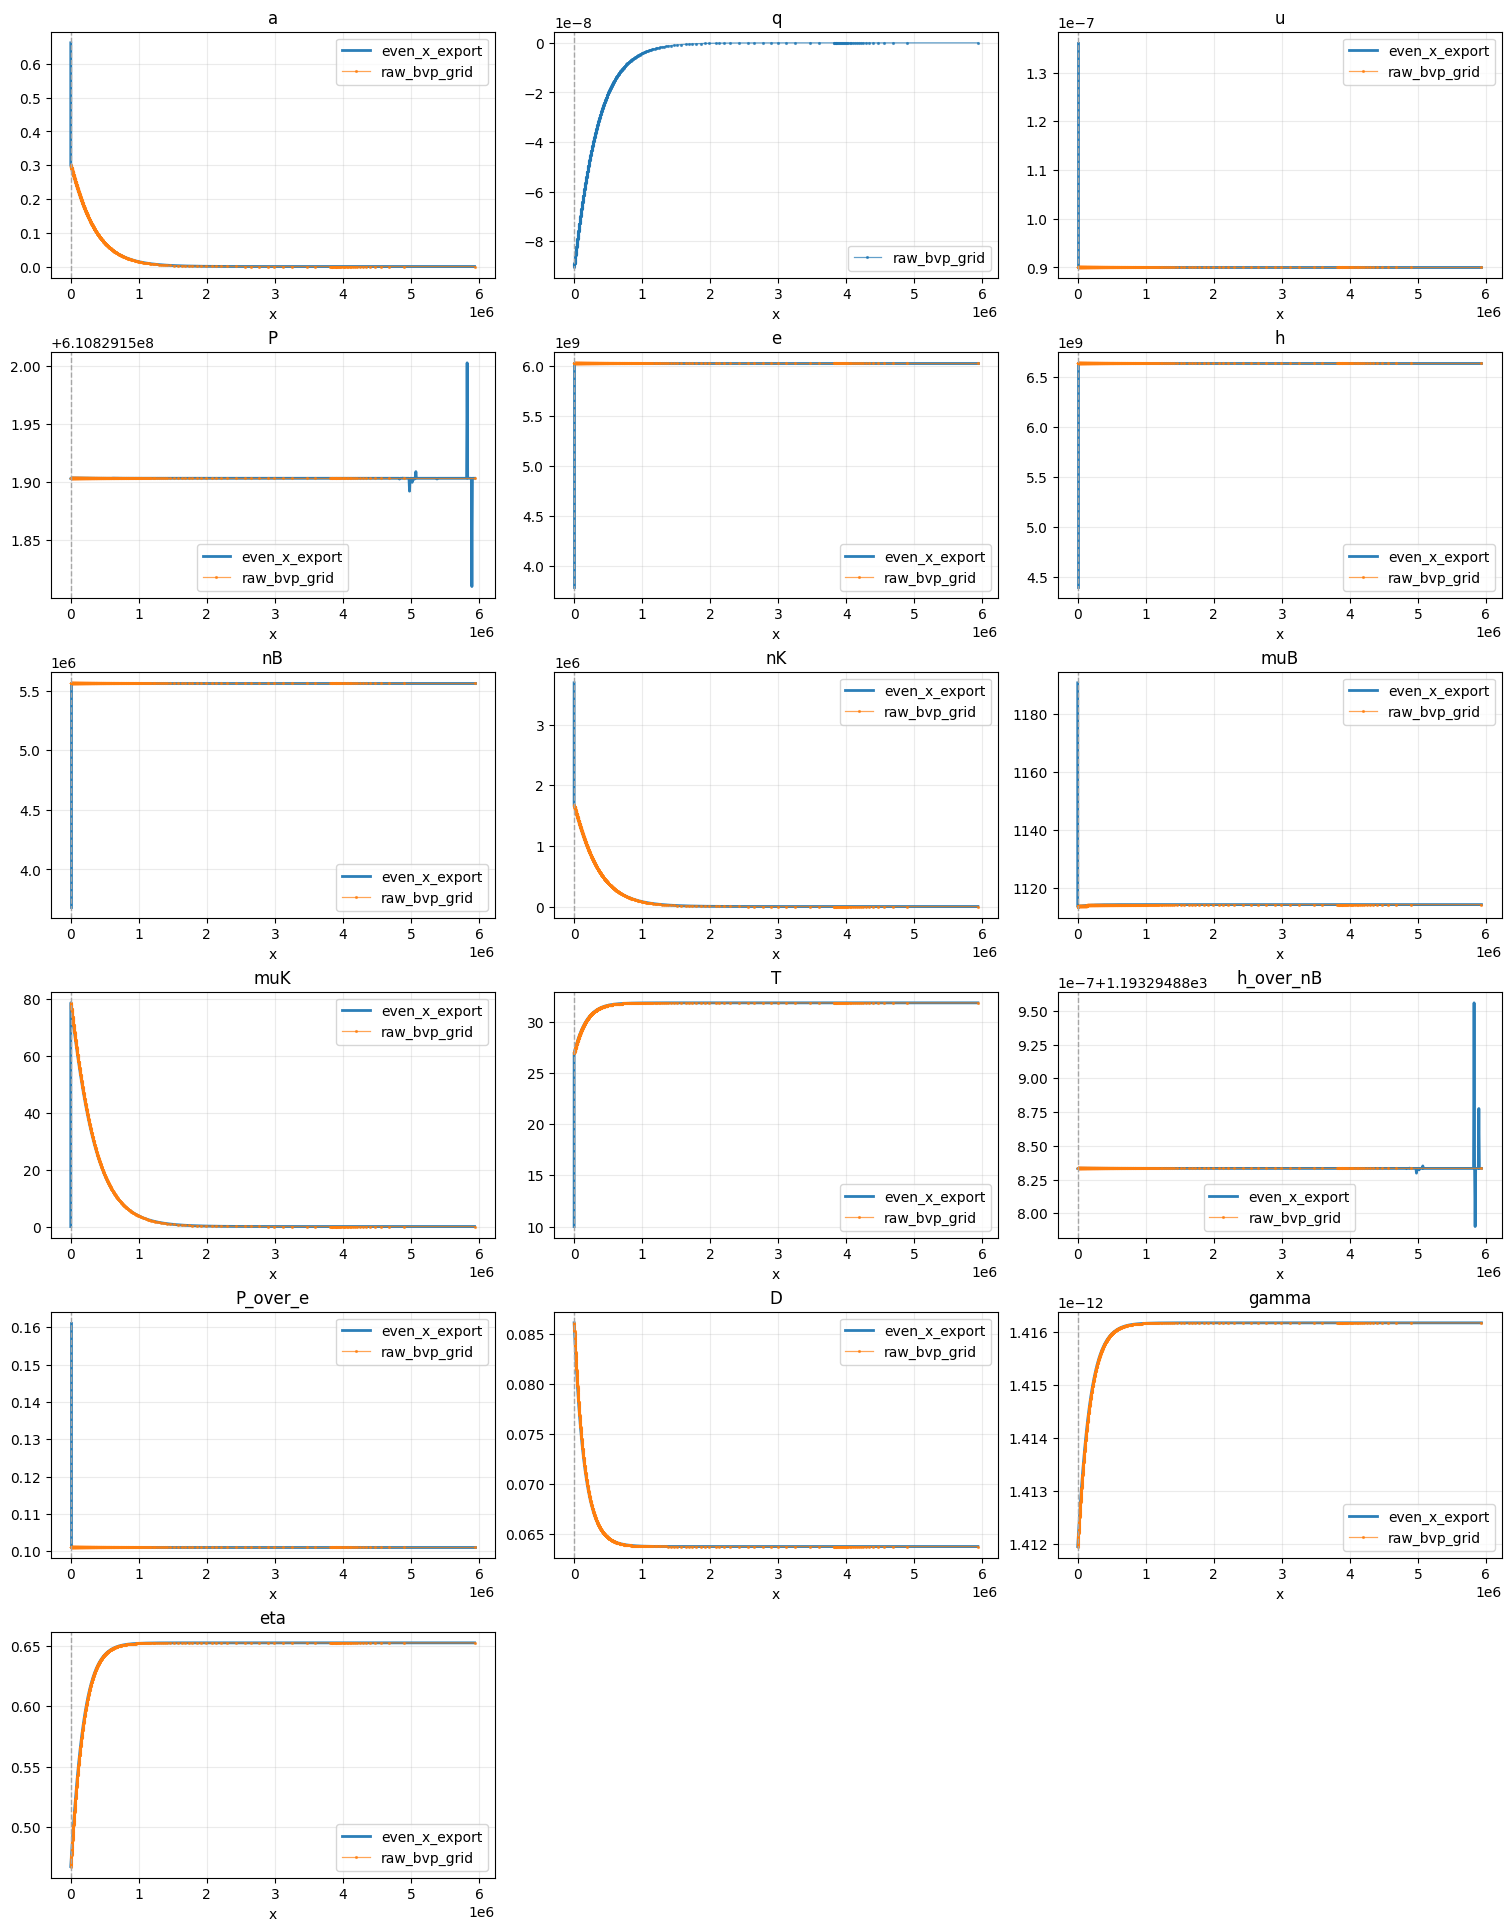

In [6]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


CSV_DIR = Path("csv_share")
STANDARD_PROFILE_COLUMNS = [
    "dummy",
    "x",
    "a",
    "u",
    "P",
    "e",
    "h",
    "nB",
    "nK",
    "muB",
    "muK",
    "T",
    "h_over_nB",
    "P_over_e",
    "D",
    "gamma",
    "eta",
]


def _latest_csv(pattern, *, reject=()):
    paths = [path for path in CSV_DIR.glob(pattern) if not any(token in path.name for token in reject)]
    if not paths:
        raise FileNotFoundError(f"No CSV files found for pattern {CSV_DIR / pattern}")
    return max(paths, key=lambda path: path.stat().st_mtime)


def _is_standard_even_profile(path):
    try:
        header = list(pd.read_csv(path, nrows=0).columns)
    except Exception:
        return False
    return header == STANDARD_PROFILE_COLUMNS


def _latest_energy_profile_paths():
    raw_path = _latest_csv("energy_conserving_raw_bvp_grid_*.csv")
    standard_candidates = [
        path
        for path in CSV_DIR.glob("energy_conserving_profiles_*.csv")
        if "raw" not in path.name and "copy" not in path.name and _is_standard_even_profile(path)
    ]
    if not standard_candidates:
        raise FileNotFoundError("No standardized evenly spaced energy-conserving profile CSV found")
    even_path = max(standard_candidates, key=lambda path: path.stat().st_mtime)
    return {
        "even_x_export": even_path,
        "raw_bvp_grid": raw_path,
    }


profile_paths = _latest_energy_profile_paths()
profile_path_df = pd.DataFrame(
    [
        {"profile": label, "path": str(path), "rows": len(pd.read_csv(path))}
        for label, path in profile_paths.items()
    ]
)
display(profile_path_df)

profiles = {label: pd.read_csv(path) for label, path in profile_paths.items()}
plot_columns = [
    column
    for column in ["a", "q", "u", "P", "e", "h", "nB", "nK", "muB", "muK", "T", "h_over_nB", "P_over_e", "D", "gamma", "eta"]
    if any(column in df.columns for df in profiles.values())
]

ncols = 3
nrows = math.ceil(len(plot_columns) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5.0 * ncols, 3.2 * nrows), constrained_layout=True)
axes = axes.ravel()
styles = {
    "even_x_export": {"lw": 2.0, "marker": None, "alpha": 0.95},
    "raw_bvp_grid": {"lw": 0.9, "marker": ".", "ms": 2.5, "alpha": 0.70},
}

for ax, column in zip(axes, plot_columns):
    for label, df in profiles.items():
        if column not in df.columns:
            continue
        if "x" not in df.columns:
            raise RuntimeError(f"{label} profile is missing the x column")
        x = df["x"].to_numpy(dtype=float)
        y = df[column].to_numpy(dtype=float)
        ax.plot(x, y, label=label, **styles.get(label, {}))
    ax.axvline(0.0, color="0.65", lw=1.0, ls="--")
    ax.set_title(column)
    ax.set_xlabel("x")
    ax.grid(True, alpha=0.25)
    ax.legend()

for ax in axes[len(plot_columns):]:
    ax.axis("off")

plt.show()


## Original ODE residue definitions

The saved energy-conserving CSV profile is checked directly against the original steady-front equations, using only the saved columns. The first row is the nuclear-side `x=0^-` state, so all derivatives use quark-side rows `1:`.

For conserved-profile equations, the plotted residue is the derivative of the conserved profile divided by that profile:

```text
r_jB = d_x(u nB) / (u nB)
r_Pi = d_x(h u^2 + P) / (h u^2 + P)
r_E = d_x(h u sqrt(1 + u^2)) / (h u sqrt(1 + u^2))
```

For the kaon-ness diffusion-reaction equation, define:

```text
Q_K = D_K d_x a - u a
R(a) = gamma_rate (a^3 + eta a)
a_mean = mean(a profile)
r_KaonNess = (d_x Q_K - R(a)) / R(a_mean)
```

Here `R(a_mean)` means the same local `gamma_rate` and `eta` profiles are used, but `a(x)` in the reaction polynomial is replaced by the quark-side profile average. The small denominator floor used below is only to prevent division by zero when a comparison profile becomes tiny.


In [7]:
from pathlib import Path
import numpy as np
import pandas as pd

try:
    profile_paths
except NameError:
    profile_paths = _latest_energy_profile_paths()

profiles_for_residue = {label: pd.read_csv(path) for label, path in profile_paths.items()}


def _require_columns(df, label, columns):
    missing = [column for column in columns if column not in df.columns]
    if missing:
        raise RuntimeError(f"{label} profile is missing required columns: {missing}")


def _quark_side_profile(label, df):
    if label == "raw_bvp_grid" or "s" in df.columns:
        return df.copy().reset_index(drop=True)
    return df.iloc[1:].copy().reset_index(drop=True)


def _dx(values, x):
    values = np.asarray(values, dtype=float)
    x = np.asarray(x, dtype=float)
    if values.size < 3:
        raise RuntimeError("Need at least three quark-side profile rows for edge_order=2 derivatives")
    return np.gradient(values, x, edge_order=2)


def _residue_over_profile(residue, comparison_profile):
    residue = np.asarray(residue, dtype=float)
    comparison_profile = np.asarray(comparison_profile, dtype=float)
    finite = np.abs(comparison_profile[np.isfinite(comparison_profile)])
    floor = max(float(np.nanmedian(finite)) if finite.size else 0.0, np.finfo(float).tiny)
    return residue / np.maximum(np.abs(comparison_profile), floor)


def _stats(values):
    values = np.asarray(values, dtype=float)
    finite = values[np.isfinite(values)]
    if finite.size == 0:
        return {
            "max_abs": np.nan,
            "rms": np.nan,
            "median_abs": np.nan,
            "p95_abs": np.nan,
            "interior_max_abs": np.nan,
        }
    abs_values = np.abs(finite)
    if values.size > 4:
        interior = values[2:-2]
        interior = interior[np.isfinite(interior)]
    else:
        interior = finite
    return {
        "max_abs": float(np.max(abs_values)),
        "rms": float(np.sqrt(np.mean(finite**2))),
        "median_abs": float(np.median(abs_values)),
        "p95_abs": float(np.percentile(abs_values, 95.0)),
        "interior_max_abs": float(np.max(np.abs(interior))) if interior.size else np.nan,
    }


def compute_profile_residues(label, df):
    base_columns = ["x", "a", "u", "P", "h", "nB", "D", "gamma", "eta"]
    _require_columns(df, label, base_columns)

    qdf = _quark_side_profile(label, df)
    x = qdf["x"].to_numpy(dtype=float)
    if not np.all(np.isfinite(x)) or not np.all(np.diff(x) > 0.0):
        raise RuntimeError(f"{label} quark-side x values must be finite and strictly increasing")

    a = qdf["a"].to_numpy(dtype=float)
    u = qdf["u"].to_numpy(dtype=float)
    nB = qdf["nB"].to_numpy(dtype=float)
    h = qdf["h"].to_numpy(dtype=float)
    P = qdf["P"].to_numpy(dtype=float)
    D = qdf["D"].to_numpy(dtype=float)
    gamma_rate = qdf["gamma"].to_numpy(dtype=float)
    eta = qdf["eta"].to_numpy(dtype=float)

    if not np.all(np.isfinite(D)) or not np.all(np.isfinite(gamma_rate)) or not np.all(np.isfinite(eta)):
        raise RuntimeError(f"{label} has non-finite D/gamma/eta values on quark-side rows")

    da_dx = _dx(a, x)
    jB_profile = u * nB
    Pi_profile = h * u**2 + P
    E_profile = h * u * np.sqrt(1.0 + u**2)
    Q_K_profile = D * da_dx - u * a
    a_mean = float(np.nanmean(a))
    R_profile = gamma_rate * (a**3 + eta * a)
    R_a_mean_profile = gamma_rate * (a_mean**3 + eta * a_mean)

    raw = {
        "r_jB": _dx(jB_profile, x),
        "r_Pi": _dx(Pi_profile, x),
        "r_KaonNess": _dx(Q_K_profile, x) - R_profile,
        "r_E": _dx(E_profile, x),
    }
    residue = {
        "r_jB": _residue_over_profile(raw["r_jB"], jB_profile),
        "r_Pi": _residue_over_profile(raw["r_Pi"], Pi_profile),
        "r_KaonNess": _residue_over_profile(raw["r_KaonNess"], R_a_mean_profile),
        "r_E": _residue_over_profile(raw["r_E"], E_profile),
    }
    if {"q_prime_solver", "R_kaon_solver", "kaon_residual_solver"}.issubset(qdf.columns):
        residue["r_KaonNess_solver"] = _residue_over_profile(
            qdf["kaon_residual_solver"].to_numpy(dtype=float),
            qdf["R_kaon_solver"].to_numpy(dtype=float),
        )
    comparison_profiles = {
        "r_jB": jB_profile,
        "r_Pi": Pi_profile,
        "r_KaonNess": R_a_mean_profile,
        "r_E": E_profile,
    }
    derived = {
        "jB_profile": jB_profile,
        "Pi_profile": Pi_profile,
        "E_profile": E_profile,
        "Q_K_profile": Q_K_profile,
        "R_profile": R_profile,
        "R_a_mean_profile": R_a_mean_profile,
        "a_mean_for_R_normalization": a_mean,
        "da_dx": da_dx,
    }

    return {
        "label": label,
        "profile": qdf,
        "x": x,
        "raw": raw,
        "residue": residue,
        "comparison_profiles": comparison_profiles,
        "derived": derived,
    }


residue_results = {
    label: compute_profile_residues(label, df)
    for label, df in profiles_for_residue.items()
}


In [8]:
summary_rows = []
for label, result in residue_results.items():
    for residue_name, values in result["residue"].items():
        row = {"profile": label, "residue": residue_name}
        row.update(_stats(values))
        summary_rows.append(row)

residue_summary_df = pd.DataFrame(summary_rows)
display(residue_summary_df)


,profile,residue,max_abs,rms,median_abs,p95_abs,interior_max_abs
0,even_x_export,r_jB,4.049533e-20,1.390692e-20,1.349844e-20,2.699689e-20,2.699689e-20
1,even_x_export,r_Pi,1.049277e-14,7.389118e-16,7.146965e-20,1.629508e-18,1.049277e-14
2,even_x_export,r_KaonNess,2.450111e-01,9.307477e-03,2.763044e-07,5.184786e-04,4.563347e-03
3,even_x_export,r_E,8.940794e-15,4.288104e-16,1.158339e-20,2.085011e-19,8.940794e-15
4,raw_bvp_grid,r_jB,4.319502e-19,1.235693e-19,5.399377e-20,2.159751e-19,4.319502e-19
5,raw_bvp_grid,r_Pi,3.811715e-19,8.029292e-20,3.722378e-22,1.905857e-19,3.811715e-19
6,raw_bvp_grid,r_KaonNess,2.661981e-03,1.023682e-04,1.066226e-06,6.706347e-06,1.955386e-04
7,raw_bvp_grid,r_E,1.390007e-18,2.390093e-19,9.266716e-20,5.560030e-19,1.204673e-18
8,raw_bvp_grid,r_KaonNess_solver,1.416169e-16,3.174534e-17,0.000000e+00,1.147275e-16,1.416169e-16


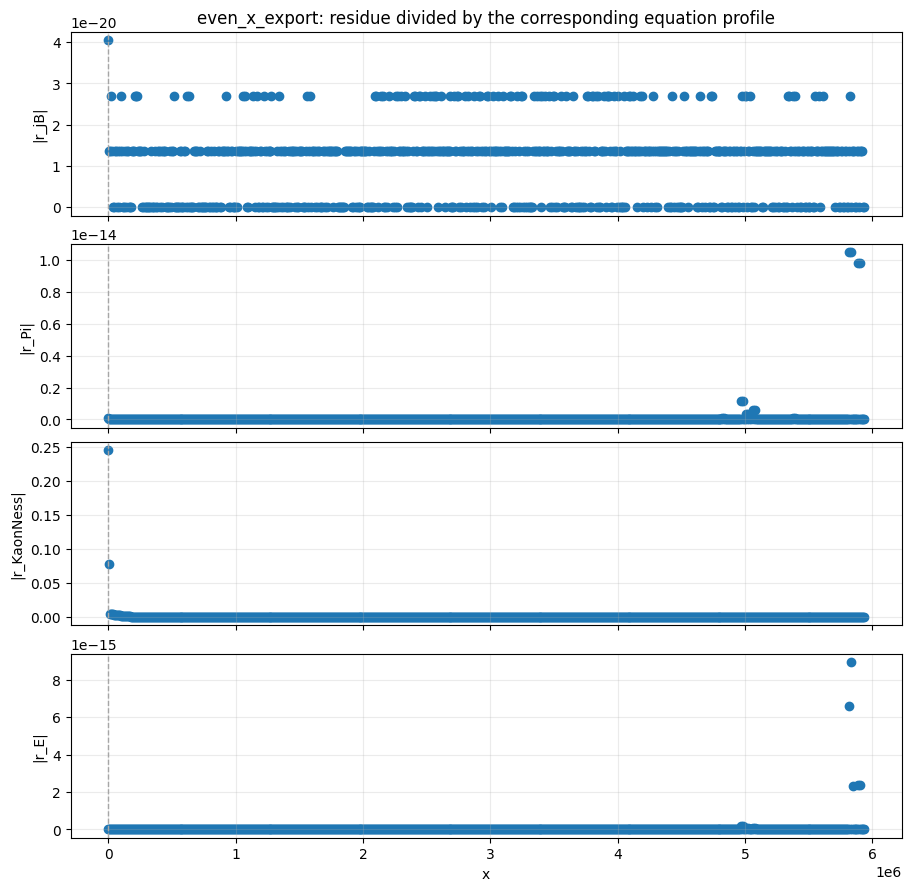

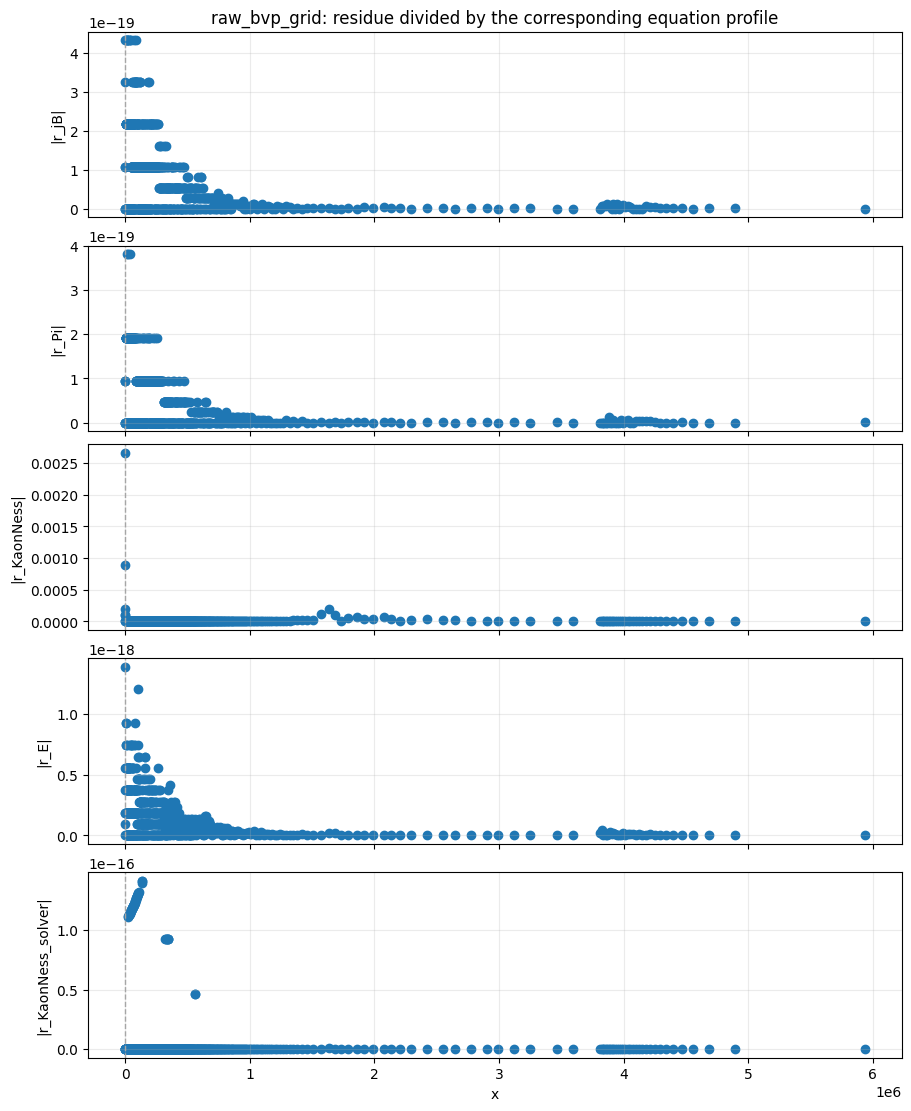

In [9]:
import matplotlib.pyplot as plt


def plot_profile_residues(result):
    label = result["label"]
    x = result["x"]
    residues = result["residue"]

    fig, axes = plt.subplots(
        len(residues),
        1,
        figsize=(9.0, max(2.2 * len(residues), 5.5)),
        sharex=True,
        constrained_layout=True,
    )
    axes = np.atleast_1d(axes)

    for ax, (residue_name, values) in zip(axes, residues.items()):
        ax.scatter(x, np.abs(values))
        ax.set_yscale("linear")
        ax.set_ylabel(f"|{residue_name}|")
        ax.axvline(0.0, color="0.65", lw=1.0, ls="--")
        ax.grid(True, which="both", alpha=0.25)

    axes[0].set_title(f"{label}: residue divided by the corresponding equation profile")
    axes[-1].set_xlabel("x")
    return fig


for result in residue_results.values():
    plot_profile_residues(result)
plt.show()
